### Desarrollo de modelos - Predicción de demanda eléctrica a 24 horas

Se implementará y evaluará los procedimientos definidos en el protocolo experimental.

El periodo de desarrollo (2015-2018) se utlizará para el entrenamiento del modelo y la validación temporal. Los datos del 2019 se reservarán para la evaluación final.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Identificar raíz del repositorio
project_root = Path.cwd()

if not (project_root / "data" / "processed").exists():
    project_root = project_root.parent

# Cargar base analítica
data_path = (
    project_root
    / "data"
    / "processed"
    / "demanda_base_analitica.csv"
)

model_df = pd.read_csv(
    data_path,
    parse_dates=["utc_timestamp", "target_timestamp"]
)

# Predictores y variable objetivo
candidate_predictors = [
    "country",
    "demand_mw",
    "lag_48h",
    "lag_72h",
    "lag_168h",
    "rolling_mean_24h",
    "rolling_mean_168h",
    "target_hour",
    "target_day",
    "target_month"
]

target = "target_demand_mw"

# Comprobación inicial
assert all(
    col in model_df.columns
    for col in candidate_predictors + [target]
)

print("Base cargada:", model_df.shape)
print("Predictores:", len(candidate_predictors))
print("Periodos:", model_df["period"].value_counts(dropna=False).to_dict())

Base cargada: (131472, 25)
Predictores: 10
Periodos: {'development': 105120, 'holdout': 26280, nan: 72}


In [3]:
validation_windows = [
    ("W1", "2016-01-01", "2017-01-01"),
    ("W2", "2017-01-01", "2018-01-01"),
    ("W3", "2018-01-01", "2019-01-01")
]

validation_partitions = {}

for name, start_date, end_date in validation_windows:

    start = pd.Timestamp(start_date, tz="UTC")
    end = pd.Timestamp(end_date, tz="UTC")

    train_mask = (
        (model_df["period"] == "development")
        & (model_df["utc_timestamp"] < start)
        & (model_df["target_timestamp"] < start)
    )

    validation_mask = (
        (model_df["period"] == "development")
        & (model_df["utc_timestamp"] >= start)
        & (model_df["utc_timestamp"] < end)
    )

    # Mismo criterio de casos completos para todos los modelos
    required = candidate_predictors + [target]

    train_df = (
        model_df.loc[train_mask]
        .dropna(subset=required)
        .copy()
    )

    validation_df = (
        model_df.loc[validation_mask]
        .dropna(subset=required)
        .copy()
    )

    assert not train_df.empty
    assert not validation_df.empty

    assert (
        train_df["target_timestamp"].max()
        < validation_df["utc_timestamp"].min()
    )

    validation_partitions[name] = {
        "train": train_df,
        "validation": validation_df
    }

    print(
        f"{name}: "
        f"Train={len(train_df):,} | "
        f"Validation={len(validation_df):,}"
    )

W1: Train=25,484 | Validation=26,352
W2: Train=51,836 | Validation=26,087
W3: Train=77,923 | Validation=25,685


### Modelos de referencia

Se evaluarán:

- Persistencia: Predice que la demanda de dentro de 24 horas será igual a la demanda actual (`demand_mw`).
- Estacional semanal: Predice que la demanda será igual a la observada una semana antes (`lag_168h`).

La siguiente función calcula MAE, RMSE y NMAE por país, también el NMAE macro. 

In [32]:
def evaluate_predictions(train_df, validation_df, predictions, model_name, window_name):
    # Ensure predictions preserve validation indices
    if not isinstance(predictions, pd.Series):
        predictions = pd.Series(
            predictions,
            index=validation_df.index
        )
    results = []

    for country in ["DE", "ES", "FR"]:
        train_country = train_df[train_df["country"] == country]
        valid_country = validation_df[validation_df["country"] == country]

        y_true = valid_country[target].to_numpy()
        y_pred = predictions.loc[valid_country.index].to_numpy()

        mae = mean_absolute_error(y_true, y_pred)
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))

        training_mean = train_country[target].mean()
        nmae = mae / training_mean

        results.append({
            "window": window_name,
            "model": model_name,
            "country": country,
            "n": len(valid_country),
            "MAE": mae,
            "RMSE": rmse,
            "NMAE": nmae
        })

    results_df = pd.DataFrame(results)

    macro_row = {
        "window": window_name,
        "model": model_name,
        "country": "Macro",
        "n": results_df["n"].sum(),
        "MAE": np.nan,
        "RMSE": np.nan,
        "NMAE": results_df["NMAE"].mean()
    }

    return pd.concat(
        [results_df, pd.DataFrame([macro_row])],
        ignore_index=True
    )

### Evaluación de los baselines

In [5]:
baseline_results = []

for window_name, partition in validation_partitions.items():
    train_df = partition["train"]
    validation_df = partition["validation"]

    # Baseline 1: persistencia
    pred_persistence = validation_df["demand_mw"]

    results_persistence = evaluate_predictions(
        train_df,
        validation_df,
        pred_persistence,
        "Persistence",
        window_name
    )

    # Baseline 2: estacional semanal
    pred_weekly = validation_df["lag_168h"]

    results_weekly = evaluate_predictions(
        train_df,
        validation_df,
        pred_weekly,
        "Weekly Seasonal",
        window_name
    )

    baseline_results.extend([
        results_persistence,
        results_weekly
    ])

baseline_results_df = pd.concat(
    baseline_results,
    ignore_index=True
)

display(
    baseline_results_df.round(4)
)

,window,model,country,n,MAE,RMSE,NMAE
0,W1,Persistence,DE,8784,4492.1990,7018.4174,0.0820
1,W1,Persistence,ES,8784,1789.8759,2760.4697,0.0630
2,W1,Persistence,FR,8784,3091.1412,4592.4669,0.0580
3,W1,Persistence,Macro,26352,NaN,NaN,0.0677
4,W1,Weekly Seasonal,DE,8784,2207.8969,4006.1230,0.0403
5,W1,Weekly Seasonal,ES,8784,1285.2696,2013.7848,0.0453
6,W1,Weekly Seasonal,FR,8784,3458.4820,4974.0852,0.0648
7,W1,Weekly Seasonal,Macro,26352,NaN,NaN,0.0501
8,W2,Persistence,DE,8760,4550.1024,7006.8546,0.0826
9,W2,Persistence,ES,8760,1841.5156,2781.0271,0.0647


Combinaciones de ventana y modelo, con métricas para DE, ES, FR y macro. El valor de NMAE macro es nuestra métrica principal de comparación. Los baselines se evaluan sobre las mismas observaciones completas que usaremos para los modelos predictivos, evitando así, comparaciones injustas por diferencias en el total de casos.

## M1 - Regresión Regularizada Ridge

La preparación de variables será:

- A las categóricas como: `country`,  `target_hour`, `target_day`, `target_month`, se les tratará como variables dummy.
- A las numéricas como: `demand_mw`, `lag_48h`, `lag_72h`, `lag_168h`, `rolling_mean_24h`, `rolling_mean_168h`, se les tratará con estandarización.

In [6]:
categorical_features = [
    "country",
    "target_hour",
    "target_day",
    "target_month"
]

numeric_features = [
    "demand_mw",
    "lag_48h",
    "lag_72h",
    "lag_168h",
    "rolling_mean_24h",
    "rolling_mean_168h"
]

ridge_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

ridge_pipeline = Pipeline(
    steps=[
        ("preprocessor", ridge_preprocessor),
        ("model", Ridge())
    ]
)

### Ajuste del hipeparámetro `alpha`

Tal parámetro controla la intensidad de la regulación. Un valor bajo se aproxima a una regresión lineal, uno mayor penaliza más los coeficientes.

Se probarán 15 valores en escala logarítmica. Cada configuración se evaluará en W1, W2 y W3

In [7]:
alpha_grid = np.logspace(-3, 4, 15)

ridge_tuning_results = []

for alpha in alpha_grid:
    for window_name, partition in validation_partitions.items():
        train_df = partition["train"]
        validation_df = partition["validation"]

        X_train = train_df[candidate_predictors]
        y_train = train_df[target]

        X_valid = validation_df[candidate_predictors]

        ridge_pipeline.set_params(model__alpha=alpha)

        ridge_pipeline.fit(X_train, y_train)

        predictions = pd.Series(
            ridge_pipeline.predict(X_valid),
            index=validation_df.index
        )

        metrics = evaluate_predictions(
            train_df,
            validation_df,
            predictions,
            f"Ridge alpha={alpha:.5g}",
            window_name
        )

        macro_nmae = metrics.loc[
            metrics["country"] == "Macro", "NMAE"
        ].iloc[0]

        ridge_tuning_results.append({
            "alpha": alpha,
            "window": window_name,
            "NMAE_macro": macro_nmae
        })

ridge_tuning_df = pd.DataFrame(ridge_tuning_results)

ridge_alpha_summary = (
    ridge_tuning_df
    .groupby("alpha", as_index=False)
    .agg(
        mean_NMAE=("NMAE_macro", "mean"),
        std_NMAE=("NMAE_macro", "std")
    )
    .sort_values("mean_NMAE")
    .reset_index(drop=True)
)

display(ridge_alpha_summary.round(5))

,alpha,mean_NMAE,std_NMAE
0,316.22777,0.04282,0.00117
1,100.00000,0.04283,0.00124
2,31.62278,0.04291,0.00120
3,10.00000,0.04296,0.00116
4,3.16228,0.04297,0.00115
5,1.00000,0.04298,0.00115
6,0.31623,0.04298,0.00115
7,0.10000,0.04298,0.00114
8,0.03162,0.04298,0.00114
9,0.01000,0.04298,0.00114


### Selección de `alpha`

Se selecciona el valor con menor `NMAE macro` promedio en las tres ventanas.

In [8]:
best_alpha = ridge_alpha_summary.loc[0, "alpha"]

print(f"Mejor alpha: {best_alpha:.5g}")
print(
    "NMAE macro promedio:",
    round(ridge_alpha_summary.loc[0, "mean_NMAE"], 5)
)

Mejor alpha: 316.23
NMAE macro promedio: 0.04282


### Evaluación del Ridge seleccionado

Volvemos a ajustar el Ridge con el `alpha` elegido en cada ventana y guardamos sus métricas por país.

In [9]:
ridge_results = []

for window_name, partition in validation_partitions.items():
    train_df = partition["train"]
    validation_df = partition["validation"]

    X_train = train_df[candidate_predictors]
    y_train = train_df[target]

    X_valid = validation_df[candidate_predictors]

    ridge_pipeline.set_params(model__alpha=best_alpha)
    ridge_pipeline.fit(X_train, y_train)

    predictions = pd.Series(
        ridge_pipeline.predict(X_valid),
        index=validation_df.index
    )

    metrics = evaluate_predictions(
        train_df,
        validation_df,
        predictions,
        "Ridge",
        window_name
    )

    ridge_results.append(metrics)

ridge_results_df = pd.concat(
    ridge_results,
    ignore_index=True
)

display(ridge_results_df.round(4))

,window,model,country,n,MAE,RMSE,NMAE
0,W1,Ridge,DE,8784,2240.1721,3318.0079,0.0409
1,W1,Ridge,ES,8784,1156.7657,1626.6156,0.0407
2,W1,Ridge,FR,8784,2316.7857,3203.8817,0.0434
3,W1,Ridge,Macro,26352,NaN,NaN,0.0417
4,W2,Ridge,DE,8760,2325.2877,3476.8884,0.0422
5,W2,Ridge,ES,8760,1255.6361,1751.8319,0.0441
6,W2,Ridge,FR,8567,2259.1954,3099.8137,0.0419
7,W2,Ridge,Macro,26087,NaN,NaN,0.0428
8,W3,Ridge,DE,8736,2373.9591,3458.3714,0.0428
9,W3,Ridge,ES,8736,1233.4642,1702.4829,0.0431


### Comparación inicial

Reunimos las métricas de los tres procedimientos para comparar sus resultados.

In [10]:
all_results_df = pd.concat(
    [
        baseline_results_df,
        ridge_results_df
    ],
    ignore_index=True
)

macro_comparison = (
    all_results_df[all_results_df["country"] == "Macro"]
    .pivot(
        index="window",
        columns="model",
        values="NMAE"
    )
)

display(macro_comparison.round(5))

print("\nNMAE macro promedio por modelo:")
display(
    macro_comparison.mean()
    .sort_values()
    .to_frame("Mean NMAE")
    .round(5)
)

model,Persistence,Ridge,Weekly Seasonal
window,,,
W1,0.06766,0.04169,0.05014
W2,0.06779,0.04275,0.05415
W3,0.06829,0.04402,0.05693



NMAE macro promedio por modelo:


,Mean NMAE
model,
Ridge,0.04282
Weekly Seasonal,0.05374
Persistence,0.06792


Ridge supera ambos baselines en las tres ventanas temporales y no solamente en el promedio global.

Se debe tener en cuenta la diferencia entre paises y la variación del desempeño entre ventanas. Además, debe considerarse en la interpretación de W2 y W3, que Francia tiene menos observaciones que Alemania y España debido a los valores faltantes. Pero por ahora, las comparaciones son válidas, aunque se debe tener presente esta diferencia de tamaño muestral.

### Interpretación de los resultados

#### Comparación general

Ridge obtiene un `NMAE macro` promedio de $0.04282$, frente a $0.05374$ del baseline estacional semanal y $0.06792$ de persistencia.

En cuanto a persistencia, Ridge reduce el `NMAE macro` cerca de un $37\%$. Mientras que en el baseline semanal, lo reduce cerca de un $20.3\%$, lo que implica que Ridge consigue mejorar una referencia que ya contiene un patrón estacional de una semana.

Si se observa la tabla de NMAE por ventanas, se aprecia que la ventaja de Ridge se mantiene en las tres ventanas. Sin embargo, el NMAE aumenta crecientemente de W1 a W3, lo que puede decir que la predicción se vuelve más dificil en periodos posteriores, aunque Ridge conserva ventaja clara sobre las referencias.

Con respecto al baseline semanal, la reducción también se mantiene, cerca de un $16.9\%$ en W1, $21\%$ en W2 y $22.6\%$ en W3.

#### Comparación entre países

Los baselines presentan patrones distintos.

- En Alemania, la persistencia tiene un `NMAE` relativamente alto, de un $8.2-8.3\%$, pero el baseline semanal mejora a un $4.0-4.6\%$.
- En España, el baseline semanal también mejora la persistencia, con un `NMAE` entre $4.5-5.1\%$.
- En Francia, por el contrario, el baseline semanal de $6.48-7.76\%$ es peor que en la persistencia, un $5.6-5.8\%$.

Esto implica que la referencia semanal funciona distinto por país. Pero aún no se puede concluir cómo se comporta Ridge en cada uno, ya que solo se tienen los promedios macro.

In [11]:
country_comparison = (
    all_results_df
    .groupby(["country", "model"])["NMAE"]
    .mean()
    .unstack("model")
)

display(country_comparison.round(5))

model,Persistence,Ridge,Weekly Seasonal
country,,,
DE,0.08259,0.04196,0.04357
ES,0.06385,0.04267,0.04787
FR,0.05731,0.04383,0.06978
Macro,0.06792,0.04282,0.05374


`NMAE` promedio de cada modelo por país.

In [12]:
display(
    ridge_results_df
    .sort_values(["window", "country"])
    .round(4)
)

,window,model,country,n,MAE,RMSE,NMAE
0,W1,Ridge,DE,8784,2240.1721,3318.0079,0.0409
1,W1,Ridge,ES,8784,1156.7657,1626.6156,0.0407
2,W1,Ridge,FR,8784,2316.7857,3203.8817,0.0434
3,W1,Ridge,Macro,26352,NaN,NaN,0.0417
4,W2,Ridge,DE,8760,2325.2877,3476.8884,0.0422
5,W2,Ridge,ES,8760,1255.6361,1751.8319,0.0441
6,W2,Ridge,FR,8567,2259.1954,3099.8137,0.0419
7,W2,Ridge,Macro,26087,NaN,NaN,0.0428
8,W3,Ridge,DE,8736,2373.9591,3458.3714,0.0428
9,W3,Ridge,ES,8736,1233.4642,1702.4829,0.0431


Métricas completas de Ridge por ventana y país.

Finalmente, con respecto a la elección del `alpha`, el mejor valor encontrado fué $\alpha=316.22777$. Sin embargo, no existe una diferencia importante entre muchos de los valores intermedios desde $\alpha=0.1$ hasta $\alpha=316$, en donde el `NMAE macro` se mantiene estable.

Esto sugiere que el rendimiento de Ridge no depende en su mayoría de una elección muy precisa del `alpha` dentro de ese rango. Lo que es una buena señal de estabilidad del hiperparámetro. No obstante, se mantiene la elección de $\alpha=316.22777$.

## M2 - Árbol de regresión podado

Se evaluará si un modelo que captura relaciones no lineales e interacciones entre variables es capaz de mejorar el desempeño de Ridge.

Se usará `DesisionTreeRegressor` con poda, por costo de complejidad (`ccp_alpha`). Se mantienen las mismas variables, ventanas temporales y observaciones completas para una justa comparación.

Se usarán los mismos predictores que en Ridge. Las variables categóricas como variables dummy, pero las seis variables numéricas de demanda no serán estandarizadas, ya que no es necesario en un árbol de decisión.

### Configuración del árbol

In [13]:
from sklearn.tree import DecisionTreeRegressor

def make_tree_pipeline(ccp_alpha):
    tree_preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                "passthrough",
                numeric_features
            ),
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_features
            )
        ]
    )

    return Pipeline(
        steps=[
            ("preprocessor", tree_preprocessor),
            (
                "model",
                DecisionTreeRegressor(
                    random_state=42,
                    ccp_alpha=ccp_alpha
                )
            )
        ]
    )

### Construcción de configuraciones de poda

El parámetro `cpp_alpha` indica cuánto se poda el árbol. Un valor de $0$ indica un árbol sin poda por costo de complejidad, mientras que valores mayores, indican una mayor penalización por complejidad (y generalmente árboles más pequeños).

Para seleccionar los valores candidatos, se usarán rutas de poda calculadas con los datos de entrenamiento de cada ventana.



### Obtener valores candidatos

In [14]:
pruning_alphas = []

for window_name, partition in validation_partitions.items():
    train_df = partition["train"]

    X_train = train_df[candidate_predictors]
    y_train = train_df[target]

    preprocessor = ColumnTransformer(
        transformers=[
            ("numeric", "passthrough", numeric_features),
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_features
            )
        ]
    )

    X_train_transformed = preprocessor.fit_transform(X_train)

    tree_probe = DecisionTreeRegressor(random_state=42)

    pruning_path = tree_probe.cost_complexity_pruning_path(
        X_train_transformed,
        y_train
    )

    positive_alphas = pruning_path.ccp_alphas[
        pruning_path.ccp_alphas > 0
    ]

    pruning_alphas.extend(positive_alphas.tolist())

# Reunir y depurar los valores candidatos
all_positive_alphas = np.asarray(pruning_alphas, dtype=float)

all_positive_alphas = all_positive_alphas[
    np.isfinite(all_positive_alphas)
]

if len(all_positive_alphas) == 0:
    raise ValueError("No se encontraron valores positivos de poda.")

tree_alpha_grid = np.unique(
    np.concatenate([
        [0.0],
        np.quantile(
            all_positive_alphas,
            np.linspace(0, 1, 19)
        )
    ])
)

print("Configuraciones de poda:", len(tree_alpha_grid))
print("Valores candidatos:")
print(tree_alpha_grid)

Configuraciones de poda: 20
Valores candidatos:
[0.00000000e+00 6.41659074e-06 3.10562992e-03 1.47838251e-02
 4.17549574e-02 9.39694270e-02 1.87627530e-01 3.43819932e-01
 6.11253674e-01 1.02890049e+00 1.70970060e+00 2.83359055e+00
 4.65972931e+00 7.72783389e+00 1.29018904e+01 2.23739783e+01
 4.14460514e+01 8.78027762e+01 2.56865784e+02 1.66150129e+08]


### Ajuste y evaluación del árbol

In [15]:
tree_tuning_results = []

for alpha in tree_alpha_grid:
    for window_name, partition in validation_partitions.items():
        train_df = partition["train"]
        validation_df = partition["validation"]

        X_train = train_df[candidate_predictors]
        y_train = train_df[target]

        X_valid = validation_df[candidate_predictors]

        tree_pipeline = make_tree_pipeline(alpha)

        tree_pipeline.fit(X_train, y_train)

        predictions = pd.Series(
            tree_pipeline.predict(X_valid),
            index=validation_df.index
        )

        metrics = evaluate_predictions(
            train_df,
            validation_df,
            predictions,
            f"Decision Tree alpha={alpha:.6g}",
            window_name
        )

        macro_nmae = metrics.loc[
            metrics["country"] == "Macro", "NMAE"
        ].iloc[0]

        tree_tuning_results.append({
            "ccp_alpha": alpha,
            "window": window_name,
            "NMAE_macro": macro_nmae
        })

tree_tuning_df = pd.DataFrame(tree_tuning_results)

tree_alpha_summary = (
    tree_tuning_df
    .groupby("ccp_alpha", as_index=False)
    .agg(
        mean_NMAE=("NMAE_macro", "mean"),
        std_NMAE=("NMAE_macro", "std")
    )
    .sort_values("mean_NMAE")
    .reset_index(drop=True)
)

display(tree_alpha_summary.round(6))

,ccp_alpha,mean_NMAE,std_NMAE
0,2.568658e+02,0.036068,0.001228
1,8.780278e+01,0.036907,0.001245
2,4.144605e+01,0.037399,0.001127
3,2.237398e+01,0.037819,0.000964
4,1.290189e+01,0.038070,0.000814
5,7.727834e+00,0.038242,0.000729
6,4.659729e+00,0.038356,0.000676
7,2.833591e+00,0.038428,0.000650
8,1.709701e+00,0.038483,0.000630
9,1.028900e+00,0.038517,0.000614


### Seleccionar nivel de poda

In [16]:
best_tree_alpha = tree_alpha_summary.loc[0, "ccp_alpha"]

print(f"Mejor ccp_alpha: {best_tree_alpha:.8g}")
print(
    "NMAE macro promedio:",
    round(tree_alpha_summary.loc[0, "mean_NMAE"], 5)
)

Mejor ccp_alpha: 256.86578
NMAE macro promedio: 0.03607


### Evaluación del árbol seleccionado

Se verá ahora los resultados y la complejidad del árbol seleccionado.

In [17]:
tree_results = []
tree_complexity = []

for window_name, partition in validation_partitions.items():
    train_df = partition["train"]
    validation_df = partition["validation"]

    X_train = train_df[candidate_predictors]
    y_train = train_df[target]

    X_valid = validation_df[candidate_predictors]

    tree_pipeline = make_tree_pipeline(best_tree_alpha)

    tree_pipeline.fit(X_train, y_train)

    predictions = pd.Series(
        tree_pipeline.predict(X_valid),
        index=validation_df.index
    )

    metrics = evaluate_predictions(
        train_df,
        validation_df,
        predictions,
        "Decision Tree",
        window_name
    )

    tree_results.append(metrics)

    fitted_tree = tree_pipeline.named_steps["model"]

    tree_complexity.append({
        "window": window_name,
        "depth": fitted_tree.get_depth(),
        "leaves": fitted_tree.get_n_leaves()
    })

tree_results_df = pd.concat(tree_results, ignore_index=True)
tree_complexity_df = pd.DataFrame(tree_complexity)

display(tree_results_df.round(4))
display(tree_complexity_df)

,window,model,country,n,MAE,RMSE,NMAE
0,W1,Decision Tree,DE,8784,1794.7498,3158.3359,0.0328
1,W1,Decision Tree,ES,8784,997.8611,1643.4047,0.0351
2,W1,Decision Tree,FR,8784,2325.5112,3472.6411,0.0436
3,W1,Decision Tree,Macro,26352,NaN,NaN,0.0372
4,W2,Decision Tree,DE,8760,1952.9760,3484.1465,0.0354
5,W2,Decision Tree,ES,8760,960.4637,1562.5509,0.0338
6,W2,Decision Tree,FR,8567,2137.5979,3224.5218,0.0397
7,W2,Decision Tree,Macro,26087,NaN,NaN,0.0363
8,W3,Decision Tree,DE,8736,1819.1375,3181.2323,0.0328
9,W3,Decision Tree,ES,8736,814.0384,1404.0375,0.0285


,window,depth,leaves
0,W1,23,2785
1,W2,28,3550
2,W3,30,3965


### Comparación con los modelos anteriores

In [18]:
all_results_df = pd.concat(
    [
        baseline_results_df,
        ridge_results_df,
        tree_results_df
    ],
    ignore_index=True
)

macro_comparison = (
    all_results_df[all_results_df["country"] == "Macro"]
    .pivot(
        index="window",
        columns="model",
        values="NMAE"
    )
)

display(macro_comparison.round(5))

print("\nNMAE macro promedio:")
display(
    macro_comparison.mean()
    .sort_values()
    .to_frame("Mean NMAE")
    .round(5)
)

model,Decision Tree,Persistence,Ridge,Weekly Seasonal
window,,,,
W1,0.03717,0.06766,0.04169,0.05014
W2,0.03629,0.06779,0.04275,0.05415
W3,0.03474,0.06829,0.04402,0.05693



NMAE macro promedio:


,Mean NMAE
model,
Decision Tree,0.03607
Ridge,0.04282
Weekly Seasonal,0.05374
Persistence,0.06792


### Interpretación de los resultados

El árbol de decisión con poda tuvo el promedio `NMAE macro` más bajo hasta el momento, de $0.03607$, superando al de Ridge de $0.04282$, al estacional semanal de $0.05374$ y al de persistencia de $0.06792$.

Se logró mejorar la precisión del modelo en un $15.8\%$ con respecto a Ridge y la mejora es consistente en las tres ventanas de validación.

Por otro lado, los valores del `NMAE macro` disminuyen de W1 a W3, lo que indica un rendimiento predictivo estable y mejorable a lo largo de los periodos evaluados.

El parámetro de poda elegido es el `ccp_alpha`=$256.86578$ que genera el `NMAE macro` más bajo. Los árboles obtenidos tienen profundidades de $23$, $28$ y $30$, y tienen $2785$, $3550$ y $3965$ hojas respectivamente. La complejidad de estos árboles aumenta mediante crece el tamaño del conjunto de entrenamiento.

Cuando se buscaba ajustar la poda, se obtuvo un valor de `ccp_alpha` bastante grande del orden de $10^8$, el cual produce un rendimiento notoriamente peor (`NMAE`=$0.339291$). Lo que dice que una poda excesiva puede producir un ajuste deficiente.

### Cuánto afecta la poda

Para ver cuanto afecta la poda en rendimiento predictivo, se cuantificará el efecto con un `ccp_alpha`=$0$ y se comparará con el ajuste con el `ccp_alpha`=$256.86578$ elegido.

In [19]:
unpruned_nmae = tree_alpha_summary.loc[
    tree_alpha_summary["ccp_alpha"] == 0,
    "mean_NMAE"
].iloc[0]

pruned_nmae = tree_alpha_summary.loc[0, "mean_NMAE"]

pruning_improvement = (
    (unpruned_nmae - pruned_nmae) / unpruned_nmae
) * 100

print(f"NMAE sin poda: {unpruned_nmae:.5f}")
print(f"NMAE con poda seleccionada: {pruned_nmae:.5f}")
print(f"Reducción relativa del NMAE: {pruning_improvement:.2f}%")

NMAE sin poda: 0.03857
NMAE con poda seleccionada: 0.03607
Reducción relativa del NMAE: 6.49%


Los valores obtenidos del `NMAE` sin poda de $0.03857$ y del `NMAE` con poda de $0.03607$, indican que aparte de reducir complejidad, también mejoran la capacidad predictiva en el conjunto de validación.

Por otro lado, los árboles tienen entre $2785$ y $3965$ hojas. Si bien sus profundidades son moderadas ($23$-$30$), la cantidad de hojas si es considerable. Esto puede deberse a que la complejidad aumenta junto con el tamaño muestral del entrenamiento y que incluso el rendimiento se mantiene o mejora levemente entre ventanas. Sin embargo, M2 sigue siendo un modelo complicado de interpretar. Finalmente, se puede decir que la configuración que se seleccionó es razonable predictivamente, pero es limitada en cuanto a interpretavilidad en la práctica.

Por ahora, M2 ofrece el mejor rendimiento predictivo entre todos los modelos evaluados.

## M3 - Random Forest

Se utilizará este método de aprendizaje para evaluar si la combinación de múltiples árboles permite mejorar el desempeño predictivo con respecto a los modelos anteriores de Ridge y ÁRbol podado.

Se mantienen las condiciones utilizadas anteriormente, la misma variable respuesta, conjunto de predictores, y particiones. Se mantiene la métrica `NMAE macro` para seleccionar hiperparámetros.

Se evaluará una grilla de no más de 20 configuraciones para examinar el efecto de la profundidad, las hojas y la complejidad en cada división.

In [21]:

from sklearn.ensemble import RandomForestRegressor

# Define preprocessing for tree-based models
tree_preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Random Forest pipeline
m3_pipeline = Pipeline(
    steps=[
        ("preprocessor", tree_preprocessor),
        ("model", RandomForestRegressor(
            random_state=42,
            n_jobs=-1
        ))
    ]
)

### Grilla de hiperparámetros

Se utilizará los hiperparámetros `n_estimators` ($200$ valores), `max_depth` (None, $15$, $25$), `min_samples_leaf` ($2$, $5$, $10$) y `max_features` ($0.7$, $1.0$). Siendo un total de 18 configuraciones.

### Construcción de la grilla

In [28]:

from itertools import product

# Define hyperparameter values
n_estimators_values = [200]
max_depth_values = [None, 15, 25]
min_samples_leaf_values = [2, 5, 10]
max_features_values = [0.7, 1.0]

# Generate all hyperparameter combinations
m3_configs = list(product(
    n_estimators_values,
    max_depth_values,
    min_samples_leaf_values,
    max_features_values
))

# Store configurations in a DataFrame
m3_grid = pd.DataFrame(
    m3_configs,
    columns=[
        "n_estimators",
        "max_depth",
        "min_samples_leaf",
        "max_features"
    ],
    dtype=object
)

print(f"Number of configurations: {len(m3_grid)}")
display(m3_grid)


Number of configurations: 18


,n_estimators,max_depth,min_samples_leaf,max_features
0,200,None,2,0.7
1,200,None,2,1.0
2,200,None,5,0.7
3,200,None,5,1.0
4,200,None,10,0.7
5,200,None,10,1.0
6,200,15,2,0.7
7,200,15,2,1.0
8,200,15,5,0.7
9,200,15,5,1.0


### Evaluación de las configuraciones

Para cada configuración, se entrenará un modelo independiente en cada ventana con sus datos de entrenamiento. Se evaluará las predicciones usando `evaluate_predictions()`. La selección considera la métrica `NMAE macro` a la que presente mejor desempeño predictivo.

In [35]:
# Store hyperparameter evaluation results
m3_tuning_results = []

for config_id, config in m3_grid.iterrows():

    # Recover max_depth, preserving None for unrestricted depth
    max_depth = config["max_depth"]

    if pd.isna(max_depth):
        max_depth = None
    else:
        max_depth = int(max_depth)

    for window_name, partition in validation_partitions.items():

        train_df = partition["train"]
        validation_df = partition["validation"]

        model = Pipeline(
            steps=[
                ("preprocessor", tree_preprocessor),
                ("model", RandomForestRegressor(
                    n_estimators=int(config["n_estimators"]),
                    max_depth=max_depth,
                    min_samples_leaf=int(config["min_samples_leaf"]),
                    max_features=float(config["max_features"]),
                    random_state=42,
                    n_jobs=-1
                ))
            ]
        )

        model.fit(
            train_df[candidate_predictors],
            train_df[target]
        )

        predictions = model.predict(
            validation_df[candidate_predictors]
        )

        results = evaluate_predictions(
            train_df,
            validation_df,
            predictions,
            model_name="Random Forest",
            window_name=window_name
        )

        # Add configuration information to the results
        results = results.copy()
        results["config_id"] = config_id
        results["n_estimators"] = int(config["n_estimators"])
        results["max_depth"] = max_depth
        results["min_samples_leaf"] = int(config["min_samples_leaf"])
        results["max_features"] = float(config["max_features"])

        m3_tuning_results.append(results)

# Combine all evaluation results
m3_tuning_results = pd.concat(
    m3_tuning_results,
    ignore_index=True
)

El código tardó 178 minutos, queda pendiente revisar si disminuir la cantidad de configuraciones para procesar menos árboles.

### Verificación de resultados

In [36]:
# Verify Random Forest tuning results

print("Results shape:", m3_tuning_results.shape)

print(
    "Configurations evaluated:",
    m3_tuning_results["config_id"].nunique()
)

print(
    "Validation windows:",
    sorted(m3_tuning_results["window"].unique())
)

print("\nRows per configuration and window:")

display(
    m3_tuning_results.groupby(
        ["config_id", "window"]
    ).size().unstack()
)

print("\nMacro results:")

display(
    m3_tuning_results[
        m3_tuning_results["country"] == "Macro"
    ].head(12)
)

Results shape: (216, 12)
Configurations evaluated: 18
Validation windows: ['W1', 'W2', 'W3']

Rows per configuration and window:


window,W1,W2,W3
config_id,,,
0,4,4,4
1,4,4,4
2,4,4,4
3,4,4,4
4,4,4,4
5,4,4,4
6,4,4,4
7,4,4,4
8,4,4,4



Macro results:


,window,model,country,n,MAE,RMSE,NMAE,config_id,n_estimators,max_depth,min_samples_leaf,max_features
3,W1,Random Forest,Macro,26352,NaN,NaN,0.028797,0,200,None,2,0.7
7,W2,Random Forest,Macro,26087,NaN,NaN,0.028598,0,200,None,2,0.7
11,W3,Random Forest,Macro,25685,NaN,NaN,0.027236,0,200,None,2,0.7
15,W1,Random Forest,Macro,26352,NaN,NaN,0.029618,1,200,None,2,1.0
19,W2,Random Forest,Macro,26087,NaN,NaN,0.029409,1,200,None,2,1.0
23,W3,Random Forest,Macro,25685,NaN,NaN,0.027792,1,200,None,2,1.0
27,W1,Random Forest,Macro,26352,NaN,NaN,0.029124,2,200,None,5,0.7
31,W2,Random Forest,Macro,26087,NaN,NaN,0.028963,2,200,None,5,0.7
35,W3,Random Forest,Macro,25685,NaN,NaN,0.027604,2,200,None,5,0.7
39,W1,Random Forest,Macro,26352,NaN,NaN,0.029834,3,200,None,5,1.0


Los promeros resultados indican que el Random Forest está obteniendo valores de `NMAE macro` cercanos a $0.028$, lo que por ahora es mejor que el árbol podado ($0.03607$) y Ridge ($0.04282$)

### Selección de hiperparámetros

In [37]:
# Aggregate macro NMAE across validation windows

m3_macro_results = m3_tuning_results[
    m3_tuning_results["country"] == "Macro"
].copy()

m3_config_summary = (
    m3_macro_results
    .groupby(
        [
            "config_id",
            "n_estimators",
            "max_depth",
            "min_samples_leaf",
            "max_features"
        ],
        dropna=False
    )
    .agg(
        mean_nmae=("NMAE", "mean"),
        std_nmae=("NMAE", "std"),
        min_nmae=("NMAE", "min"),
        max_nmae=("NMAE", "max"),
        n_windows=("window", "nunique")
    )
    .reset_index()
    .sort_values("mean_nmae")
    .reset_index(drop=True)
)

display(m3_config_summary)

,config_id,n_estimators,max_depth,min_samples_leaf,max_features,mean_nmae,std_nmae,min_nmae,max_nmae,n_windows
0,0,200,NaN,2,0.7,0.028210,0.000850,0.027236,0.028797,3
1,12,200,25.0,2,0.7,0.028224,0.000842,0.027256,0.028781,3
2,6,200,15.0,2,0.7,0.028474,0.000717,0.027646,0.028898,3
3,14,200,25.0,5,0.7,0.028533,0.000842,0.027565,0.029098,3
4,2,200,NaN,5,0.7,0.028564,0.000835,0.027604,0.029124,3
5,8,200,15.0,5,0.7,0.028689,0.000791,0.027776,0.029164,3
6,1,200,NaN,2,1.0,0.028940,0.000999,0.027792,0.029618,3
7,13,200,25.0,2,1.0,0.028942,0.001007,0.027787,0.029639,3
8,7,200,15.0,2,1.0,0.029177,0.000882,0.028159,0.029688,3
9,3,200,NaN,5,1.0,0.029192,0.000956,0.028093,0.029834,3


### Identificación de la mejor configuración

In [38]:
# Select the configuration with the lowest mean macro NMAE

best_m3_config = m3_config_summary.iloc[0]

print("Best Random Forest configuration:")
display(best_m3_config.to_frame(name="Value"))

print("\nBest mean macro NMAE:", round(best_m3_config["mean_nmae"], 5))
print("Standard deviation:", round(best_m3_config["std_nmae"], 5))

Best Random Forest configuration:


,Value
config_id,0.000000
n_estimators,200.000000
max_depth,NaN
min_samples_leaf,2.000000
max_features,0.700000
mean_nmae,0.028210
std_nmae,0.000850
min_nmae,0.027236
max_nmae,0.028797
n_windows,3.000000



Best mean macro NMAE: 0.02821
Standard deviation: 0.00085


La configuración elegida para el Random Forest utilizó $200$ árboles, sin restricción de profundidad máxima, al menos dos observaciones por hoja y seleccionando un $70\%$ de los predictores en cada división.

La configuración obtuvo un `NMAE macro` promedio de $0.02821$, con una desviación estandar de $0.00085$ entre las tres ventanas de validación. El bajo valor de la variabiliad sugiere un desempeño temporal estable dentro del periodo de desarrollo.

### Evaluación por país y ventana

#### Desempeño por país

In [39]:
# Extract country-level results for the selected configuration

best_config_id = int(best_m3_config["config_id"])

m3_best_country_results = (
    m3_tuning_results[
        (m3_tuning_results["config_id"] == best_config_id) &
        (m3_tuning_results["country"] != "Macro")
    ]
    .sort_values(["country", "window"])
    .reset_index(drop=True)
)

display(
    m3_best_country_results[
        ["window", "country", "n", "MAE", "RMSE", "NMAE"]
    ]
)

,window,country,n,MAE,RMSE,NMAE
0,W1,DE,8784,1429.637386,2464.154168,0.026096
1,W2,DE,8760,1536.487791,2597.877932,0.027877
2,W3,DE,8736,1460.847819,2394.862021,0.026335
3,W1,ES,8784,754.712498,1200.743923,0.026578
4,W2,ES,8760,749.944016,1213.572237,0.026357
5,W3,ES,8736,626.529927,1090.367505,0.021914
6,W1,FR,8784,1798.173598,2700.425895,0.033716
7,W2,FR,8567,1700.027668,2487.009841,0.031559
8,W3,FR,8213,1805.287483,2703.604840,0.033458


### `NMAE` por país

In [40]:
# Compare country-level NMAE across validation windows

m3_country_nmae = m3_best_country_results.pivot(
    index="country",
    columns="window",
    values="NMAE"
)

m3_country_nmae["Mean NMAE"] = m3_country_nmae.mean(axis=1)

display(m3_country_nmae.round(5))

window,W1,W2,W3,Mean NMAE
country,,,,
DE,0.02610,0.02788,0.02633,0.02677
ES,0.02658,0.02636,0.02191,0.02495
FR,0.03372,0.03156,0.03346,0.03291


España presenta el mejor desempeño relativo. Su `NMAE` promedio es de $0.02495$ y además mejora considerablemente en W3, alcanzando un $0.02191$. Por otro lado, Alemania presenta una estabilidad notable, con un `NMAE` promedio de $0.02677$ y con variaciones temporales con una variación pequeña (entre $0.026096 y 0.027877$). Por ultimo, Francia presentasistemáticamente un mayor error relativo, sus valores de `NMAE` promedio varian entre $0.031559$ y $0.033716$. Esto sugiere que es más dificil predecir la demanda Francesa utiizando los predictores disponibles. Aunque no podríamos atribuir alguna causa específica.

### Estabilidad temporal

Variación del `NMAE macro` entre las ventanas W1, W2 y W3 para evaluar consistencia temporal de la configuración elegida.

In [41]:
# Extract macro NMAE across validation windows

m3_best_macro_results = (
    m3_macro_results[
        m3_macro_results["config_id"] == best_config_id
    ]
    .sort_values("window")
    .reset_index(drop=True)
)

display(
    m3_best_macro_results[
        ["window", "n", "NMAE"]
    ].round(5)
)

,window,n,NMAE
0,W1,26352,0.02880
1,W2,26087,0.02860
2,W3,25685,0.02724


Aquí el error disminuye progresivamente desde W1 hasta W3, la diferencia total es de $0.001561$. Esto indica que el rendimiento predictivo no depende unicamente de una ventana en particular, más aún, se observa una mejora en la última ventana. Sin embargo, la variación es más una variabiidad descriptiva y no una medida de incertidumbre inferencial.

### Gráfico de estabilidad

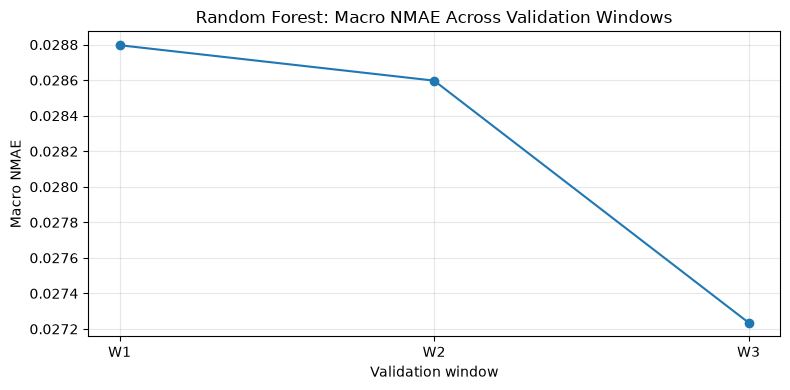

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.plot(
    m3_best_macro_results["window"],
    m3_best_macro_results["NMAE"],
    marker="o"
)

plt.title("Random Forest: Macro NMAE Across Validation Windows")
plt.xlabel("Validation window")
plt.ylabel("Macro NMAE")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Análisis de complejidad computacional

Vamos a cuantificar la complejidad estructural. 

Se entrenará una sola vez la configuración elegida usando la partición de entrenamiento W3, la cual tiene el mayor conjunto de entrenamiento de las tress ventanas. Además se podrá reutilizar el modelo para estudiar la importancia de los predictores.

### Ajuste del modelo seleccionado

In [43]:
import time

# Recover the W3 training partition
train_w3 = validation_partitions["W3"]["train"]

# Fit the selected Random Forest configuration
m3_best_model_w3 = Pipeline(
    steps=[
        ("preprocessor", tree_preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=200,
            max_depth=None,
            min_samples_leaf=2,
            max_features=0.7,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

start_time = time.perf_counter()

m3_best_model_w3.fit(
    train_w3[candidate_predictors],
    train_w3[target]
)

m3_fit_time = time.perf_counter() - start_time

print(f"Training time: {m3_fit_time:.2f} seconds")
print(f"Training time: {m3_fit_time / 60:.2f} minutes")

Training time: 523.48 seconds
Training time: 8.72 minutes


### Complejidad estructural

In [44]:
# Extract individual trees from the fitted Random Forest

rf_model = m3_best_model_w3.named_steps["model"]

tree_depths = [
    tree.tree_.max_depth
    for tree in rf_model.estimators_
]

tree_nodes = [
    tree.tree_.node_count
    for tree in rf_model.estimators_
]

tree_leaves = [
    tree.tree_.n_leaves
    for tree in rf_model.estimators_
]

m3_complexity = pd.DataFrame({
    "Metric": [
        "Number of trees",
        "Average depth",
        "Maximum depth",
        "Average nodes per tree",
        "Average leaves per tree",
        "Total nodes in ensemble",
        "Total leaves in ensemble"
    ],
    "Value": [
        len(rf_model.estimators_),
        np.mean(tree_depths),
        np.max(tree_depths),
        np.mean(tree_nodes),
        np.mean(tree_leaves),
        np.sum(tree_nodes),
        np.sum(tree_leaves)
    ]
})

display(m3_complexity.round(2))

,Metric,Value
0,Number of trees,200.00
1,Average depth,38.09
2,Maximum depth,45.00
3,Average nodes per tree,42947.28
4,Average leaves per tree,21474.14
5,Total nodes in ensemble,8589456.00
6,Total leaves in ensemble,4294828.00


### Interpretación de complejidad

El modelo de Random Forest alcanza el mejor desempeño de los modelos evaluados, y esta mejora se logra a costa de una mayor complejidad estructural y computacional. El ensamble contiene $200$ árboles, con una profundidad promedio de $38.09$ niveles y cerca de unos $8.59$ millones de nodos totales. Además, su ajuste sobre W3 requirió un total de $8.72$ minutos.

Finalmente, la elección del modelo de Random Forest representa una mejora sustancial a nivel predictivo con respecto a los modelos anteriores, a cambio de una mayor complejidad. Sin embargo, ese mayor costo computacional y menor interpretabilidad deben evaluarse con respecto a su utilizacion en la práctica frente a modelos menos complejos.

### Importancia de los predictores

Se usará `feature_importances_`, que es la importancia basada en la reducción de impureza de loa árboles, se consideran igualmente sus limitaciones ante predictores correlacionados y que no representa necesariamente un efecto causal.

Esto identificará qué predictores contribuyen más a las divisiones de los árboles del ensamble

In [47]:
# Group transformed feature importance by original predictor

def get_original_predictor(feature_name):

    for predictor in candidate_predictors:

        if (
            feature_name == f"num__{predictor}"
            or feature_name == f"cat__{predictor}"
            or feature_name.startswith(f"cat__{predictor}_")
        ):
            return predictor

    return feature_name


feature_importance["original_predictor"] = (
    feature_importance["feature"].apply(get_original_predictor)
)

m3_grouped_importance = (
    feature_importance
    .groupby("original_predictor")["importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

display(m3_grouped_importance)

,original_predictor,importance
0,lag_168h,0.652156
1,demand_mw,0.217222
2,lag_48h,0.079801
3,rolling_mean_168h,0.016286
4,target_day,0.012365
5,lag_72h,0.012025
6,rolling_mean_24h,0.004599
7,target_month,0.002907
8,country,0.001369
9,target_hour,0.001270


### Visualización de importancia

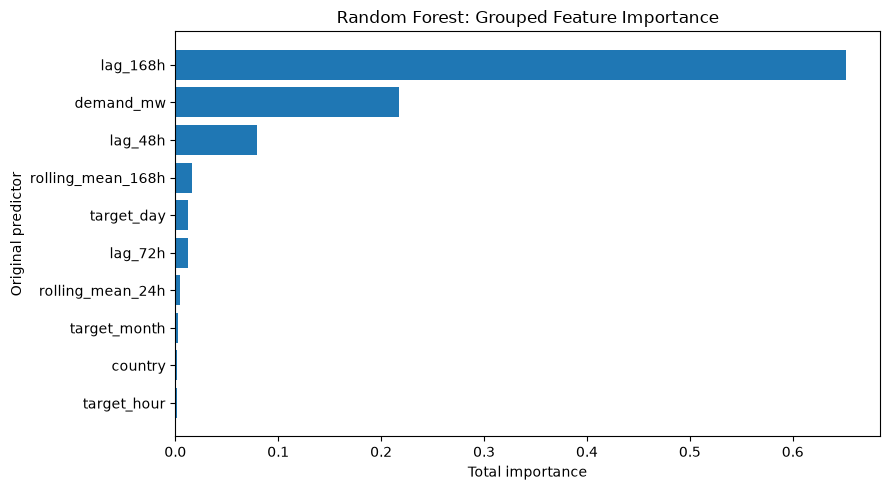

In [49]:
plt.figure(figsize=(9, 5))

plt.barh(
    m3_grouped_importance["original_predictor"][::-1],
    m3_grouped_importance["importance"][::-1]
)

plt.title("Random Forest: Grouped Feature Importance")
plt.xlabel("Total importance")
plt.ylabel("Original predictor")

plt.tight_layout()
plt.show()

### Interpretacion de la importancia de predictores

Se aprecia que los predictores: `lag_168h`, `demand_mw` (`lag_24h`) y `lag_48h` explican un $94.92\%$ de la varianza total. El que domina el modelo es `lag_168h`, que representa la demanda registrada a la misma hora, pero una semana antes, su contribución del $65.22\%$ indica que el patrón semanal es una señal predictiva fundamental para anticipar la demanda a 24 horas. Y esto puede tomar sentido, ya que los patrones asociados a los días de semana y sus horarios, suele repetirse.

Por otro lado, `demand_mw`, la demanda observada en el momento `t` del pronostico, representa un $21.72\%$ de la varianza, lo que indica que el nivel actual también es relevante. Finalemnte, `lag_48h` representa el $7.98\%$ de la varianza, sugiere que la demanda de hace dos días también influye en la predicción de la demanda a 24 horas, pero en menor medida.

### Conclusión del desempeño

EL modelo M3 de Random Forest obtuvo el mejor desempeño predictivo entre los tres modelos principales, con un `NMAE macro` de $0.02821$. Lo que representa una mejora del $34.1\%$ con respecto a Ridge y una mejora del $21.8\%$ con respecto al Árbol de decisión con poda.

La mejora predictiva se obtuvo mediante un ensamble de $200$ árboles, de una complejidad y costo computacional considerable. El análisis de importancia señalo que la demanda a la misma hora, una semana anterior es un predictor dominante, seguido de la demanda actual en tiempo `t` y la demanda $48$ horas antes.

## Comparación global de modelos

Compararemos el desempeño de los métodos evaluados: persistencia, estacionalidad semanal, Ridge, Árbol de decisión con poda, Rando Forest.

Se identificará cuál de ellos presenta el menor `NMAE macro` y evaluaremos si su desempeño es consistente a través de las ventanas temporales.

Se examinará las mejoras relativas entre modelos y se dará contexto al desempeño predictivo considerando la complejidad.

In [53]:
m3_selected_results = m3_tuning_results[
    (m3_tuning_results["config_id"] == 0) &
    (m3_tuning_results["country"] == "Macro")
].copy()

display(
    m3_selected_results[
        ["window", "config_id", "n_estimators",
         "max_depth", "min_samples_leaf",
         "max_features", "NMAE"]
    ]
)

,window,config_id,n_estimators,max_depth,min_samples_leaf,max_features,NMAE
3,W1,0,200,None,2,0.7,0.028797
7,W2,0,200,None,2,0.7,0.028598
11,W3,0,200,None,2,0.7,0.027236


### Consolidación de resultados

Se integran los tres modelos desarrollados, considerando las observaciones macro para cada ventana temporal. Así se comparará el desempeño predictivo bajo un criterio común.

In [56]:
# Combine results from all evaluated methods

baseline_df = pd.concat(baseline_results, ignore_index=True)
ridge_df = pd.concat(ridge_results, ignore_index=True)
tree_df = pd.concat(tree_results, ignore_index=True)

m3_df = m3_selected_results.copy()

global_results = pd.concat(
    [baseline_df, ridge_df, tree_df, m3_df],
    ignore_index=True
)

# Keep only macro-level results
global_results = global_results[
    global_results["country"] == "Macro"
].copy()

# Select relevant columns
global_results = global_results[
    ["model", "window", "NMAE"]
].sort_values(["model", "window"])

display(global_results)

,model,window,NMAE
39,Decision Tree,W1,0.037169
43,Decision Tree,W2,0.036290
47,Decision Tree,W3,0.034744
3,Persistence,W1,0.067664
11,Persistence,W2,0.067795
19,Persistence,W3,0.068287
48,Random Forest,W1,0.028797
49,Random Forest,W2,0.028598
50,Random Forest,W3,0.027236
27,Ridge,W1,0.041690


### Tabla comparativa

In [57]:
# Create global model comparison table

global_comparison = (
    global_results
    .pivot(index="model", columns="window", values="NMAE")
    .reindex(columns=["W1", "W2", "W3"])
)

global_comparison["Mean NMAE"] = global_comparison.mean(axis=1)
global_comparison["SD NMAE"] = global_comparison[
    ["W1", "W2", "W3"]
].std(axis=1, ddof=1)

global_comparison = global_comparison.sort_values("Mean NMAE")

display(global_comparison.round(5))

window,W1,W2,W3,Mean NMAE,SD NMAE
model,,,,,
Random Forest,0.02880,0.02860,0.02724,0.02821,0.00085
Decision Tree,0.03717,0.03629,0.03474,0.03607,0.00123
Ridge,0.04169,0.04275,0.04402,0.04282,0.00117
Weekly Seasonal,0.05014,0.05415,0.05693,0.05374,0.00341
Persistence,0.06766,0.06779,0.06829,0.06792,0.00033


Comparando todos los modelos evaluados, se aprecian diferencias de desempeño predictivo. Se considera tanto su error predictivo, como su variabilidad temporal, de tal forma que la selección no dependa solo del resultado de una ventana específica.

Un menor `NMAE macro` indica un menor error relativo promedio entre los tres paises. Así mismo, una menor desviación estandar entre ventanas indica una mayor consistencia temporal del desempeño.

En este caso, Random Forest obtiene el menor `NMAE macro` en las tres ventanas y además, su variabilidad temporal es baja (`sd`=$0.00085$)

### Comparación visual del desempeño

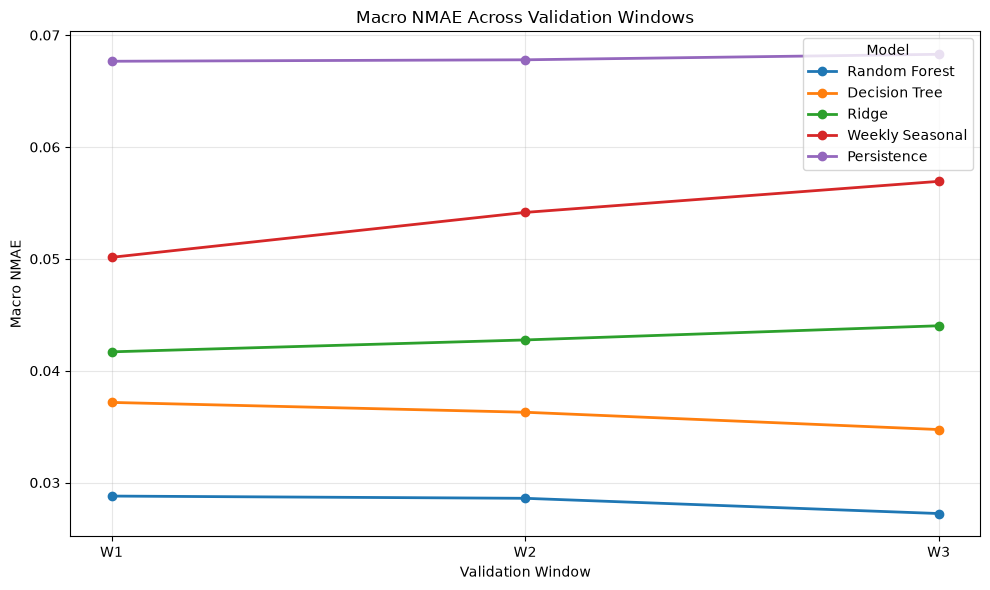

In [58]:
import matplotlib.pyplot as plt

windows = ["W1", "W2", "W3"]

plt.figure(figsize=(10, 6))

for model_name in global_comparison.index:
    plt.plot(
        windows,
        global_comparison.loc[model_name, windows],
        marker="o",
        linewidth=2,
        label=model_name
    )

plt.title("Macro NMAE Across Validation Windows")
plt.xlabel("Validation Window")
plt.ylabel("Macro NMAE")
plt.legend(title="Model")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Mejoras relativas de Random Forest

In [59]:
rf_mean = global_comparison.loc["Random Forest", "Mean NMAE"]

comparison_models = [
    "Decision Tree",
    "Ridge",
    "Weekly Seasonal",
    "Persistence"
]

relative_improvements = pd.DataFrame({
    "Reference Model": comparison_models,
    "Mean NMAE": [
        global_comparison.loc[m, "Mean NMAE"]
        for m in comparison_models
    ]
})

relative_improvements["RF Improvement (%)"] = (
    (relative_improvements["Mean NMAE"] - rf_mean)
    / relative_improvements["Mean NMAE"] * 100
)

display(relative_improvements.round(2))

,Reference Model,Mean NMAE,RF Improvement (%)
0,Decision Tree,0.04,21.79
1,Ridge,0.04,34.12
2,Weekly Seasonal,0.05,47.51
3,Persistence,0.07,58.46


En comparación con el Árbol de decisión podado, el Random Forest reduce el error en un $21.79\%$, y con respecto a Ridge, reduce el error en un $34.12\%$. También supera ampliamente a los modelos de referencia: persistencia y estacional semanal.

### Comparación del error promedio y variabilidad

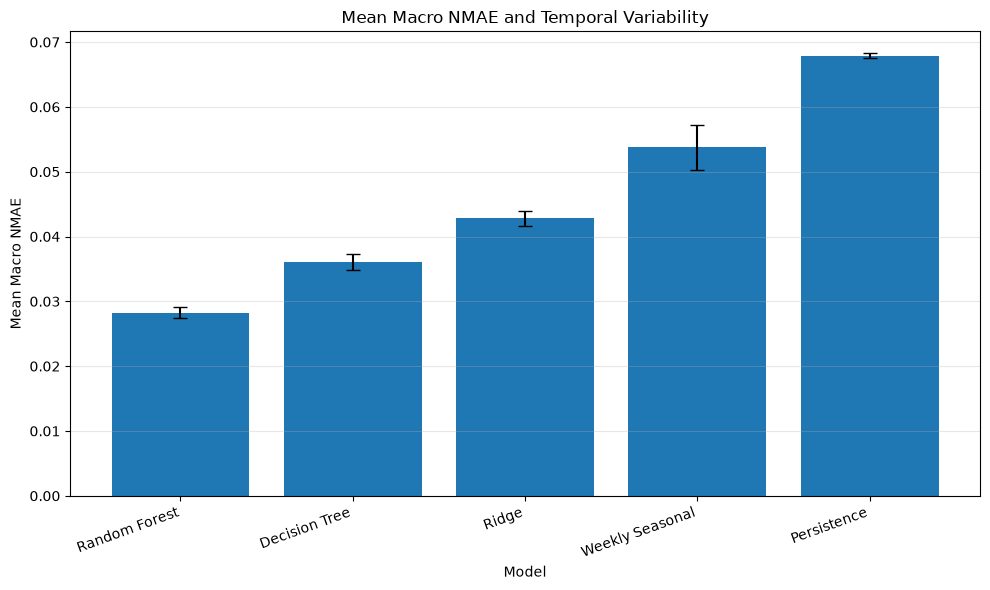

In [60]:
plt.figure(figsize=(10, 6))

plt.bar(
    global_comparison.index,
    global_comparison["Mean NMAE"],
    yerr=global_comparison["SD NMAE"],
    capsize=5
)

plt.title("Mean Macro NMAE and Temporal Variability")
plt.xlabel("Model")
plt.ylabel("Mean Macro NMAE")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Este gráfico contempla una evolución temporal, y muestra el promedio y la desviación estandar de cada modelo evaluado.

Finalmente, en conjunto, estos resultados ponen al Random Forest como el candidato principal para la evaluación final, y se le aplicarán posteriores analisis de sensibilidad, diagnósticos e incertidumbre.

### Exportación de resultados

Se guardan las configuraciones y resultados relevantes en archivos externos para ser reutilizados en otros archivos del proyecto. Se guardarán tres archivos:

- `selected_configuration`: configuraciones de los tres modelos evaluados.
- `validation_objects`: Comparación global, por país y periodos.
- `global_compairson`: Comparación global de modelos.

In [61]:
# Define the selected configurations of the three fitted models

selected_configurations = pd.DataFrame([
    {
        "model": "Ridge",
        "alpha": 316.22777,
        "ccp_alpha": None,
        "n_estimators": None,
        "max_depth": None,
        "min_samples_leaf": None,
        "max_features": None,
        "random_state": None
    },
    {
        "model": "Decision Tree",
        "alpha": None,
        "ccp_alpha": 256.86578,
        "n_estimators": None,
        "max_depth": None,
        "min_samples_leaf": None,
        "max_features": None,
        "random_state": 42
    },
    {
        "model": "Random Forest",
        "alpha": None,
        "ccp_alpha": None,
        "n_estimators": 200,
        "max_depth": "None",
        "min_samples_leaf": 2,
        "max_features": 0.7,
        "random_state": 42
    }
])

display(selected_configurations)

,model,alpha,ccp_alpha,n_estimators,max_depth,min_samples_leaf,max_features,random_state
0,Ridge,316.22777,NaN,NaN,NaN,NaN,NaN,NaN
1,Decision Tree,NaN,256.86578,NaN,NaN,NaN,NaN,42.0
2,Random Forest,NaN,NaN,200.0,None,2.0,0.7,42.0


In [67]:
# Extract macro-level results for the selected Random Forest configuration
m3_macro_results = (
    m3_tuning_results[
        (m3_tuning_results["config_id"] == 0)
        & (m3_tuning_results["country"] == "Macro")
    ][["window", "NMAE"]]
    .copy()
)

m3_macro_results["model"] = "Random Forest"
m3_macro_results["country"] = "Macro"
m3_macro_results["n"] = None
m3_macro_results["MAE"] = None
m3_macro_results["RMSE"] = None

m3_macro_results = m3_macro_results[
    ["model", "window", "country", "n", "MAE", "RMSE", "NMAE"]
].copy()

display(m3_macro_results)

,model,window,country,n,MAE,RMSE,NMAE
3,Random Forest,W1,Macro,None,None,None,0.028797
7,Random Forest,W2,Macro,None,None,None,0.028598
11,Random Forest,W3,Macro,None,None,None,0.027236


In [69]:
validation_results = pd.concat(
    [
        baseline_results_df,
        ridge_results_df,
        tree_results_df,
        m3_best_country_results,
        m3_macro_results
    ],
    ignore_index=True
)

validation_results = validation_results[
    ["model", "window", "country", "n", "MAE", "RMSE", "NMAE"]
].copy()

validation_results = (
    validation_results
    .sort_values(["model", "window", "country"])
    .reset_index(drop=True)
)

display(validation_results)

,model,window,country,n,MAE,RMSE,NMAE
0,Decision Tree,W1,DE,8784,1794.749788,3158.335893,0.032761
1,Decision Tree,W1,ES,8784,997.861068,1643.404702,0.035141
2,Decision Tree,W1,FR,8784,2325.511237,3472.641142,0.043604
3,Decision Tree,W1,Macro,26352,NaN,NaN,0.037169
4,Decision Tree,W2,DE,8760,1952.975955,3484.146495,0.035434
5,Decision Tree,W2,ES,8760,960.463676,1562.550943,0.033756
6,Decision Tree,W2,FR,8567,2137.597885,3224.521833,0.039681
7,Decision Tree,W2,Macro,26087,NaN,NaN,0.036290
8,Decision Tree,W3,DE,8736,1819.137516,3181.232294,0.032794
9,Decision Tree,W3,ES,8736,814.038355,1404.037516,0.028472


### Exportar

In [72]:
from pathlib import Path

# Locate project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Create output directory
results_dir = project_root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

# Export results
selected_configurations.to_csv(
    results_dir / "selected_configurations.csv",
    index=False
)

validation_results.to_csv(
    results_dir / "validation_results.csv",
    index=False
)

global_comparison.to_csv(
    results_dir / "global_comparison.csv",
    index=True
)

print("Files saved successfully:")
for file in results_dir.iterdir():
    print("-", file.name)

Files saved successfully:
- global_comparison.csv
- selected_configurations.csv
- validation_results.csv
